# Double-well potential

$$dX_t=(0.5X_t-X_t^3)\,dt+(1+0.25X_t^2)\,dB_t^P.$$

The drift differential is interpreted as $dt$ in the supplied image.
Use $X_0=1$, $T=200$, $\Delta t=0.0002$, and seed 42. A longer observation
period lets the path visit both wells. The coefficients and seed are fixed;
regression settings are selected from observed data.

Compare Method 1, Method 2, and ODE2 using the existing models. These methods
receive $\mu(X_0)=-0.5$; ODE2 also receives $\mu'(X_0)=-2.5$.
A separate increment fit estimates the drift from $X$ alone, with no supplied
drift or slope. It is a comparison, not a replacement for the paper's methods.

In [1]:
from pathlib import Path
import os
import sys

roots = [Path.cwd(), *Path.cwd().parents, Path('/content/SSISDE')]
PROJECT_ROOT = next((p for p in roots if (p / 'models/stochastic_sindy.py').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Open the SSISDE checkout first. On Colab, use the Black-Scholes setup cell.')
sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT / 'experiments/double_well')
RESULTS = PROJECT_ROOT / 'outputs/double_well'
RESULTS.mkdir(parents=True, exist_ok=True)

In [2]:
%pip install -q -r ../../requirements.txt


[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: /Users/munawarali/Documents/GitHub/SSISDE/.venv/bin/python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [3]:
import json
import warnings
import numpy as np
import matplotlib.pyplot as plt
from numpy.polynomial.polynomial import polyval
import pysindy as ps
from sklearn import linear_model
from sklearn.linear_model import Lasso, ElasticNet
from sklearn.model_selection import TimeSeriesSplit
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits
from tqdm import tqdm
import iisignature

from models.diffusion_tuning import fit_diffusion
from models.polynomial_diffusion import diffusion_derivatives
from models.noise_recovery import recover_noise
from models.increment_drift import fit_increment_drift


def rmse(estimate, actual):
    return float(np.sqrt(np.mean((np.asarray(estimate) - actual)**2)))

/Users/munawarali/Documents/GitHub/SSISDE/.venv/lib/python3.11/site-packages/pysindy/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound


## Simulate $X$

N = 1,000,000, T = 200, dt = 0.0002, seed = 42
Observed range: [-2.573, 2.762]
Time below zero: 57.2%


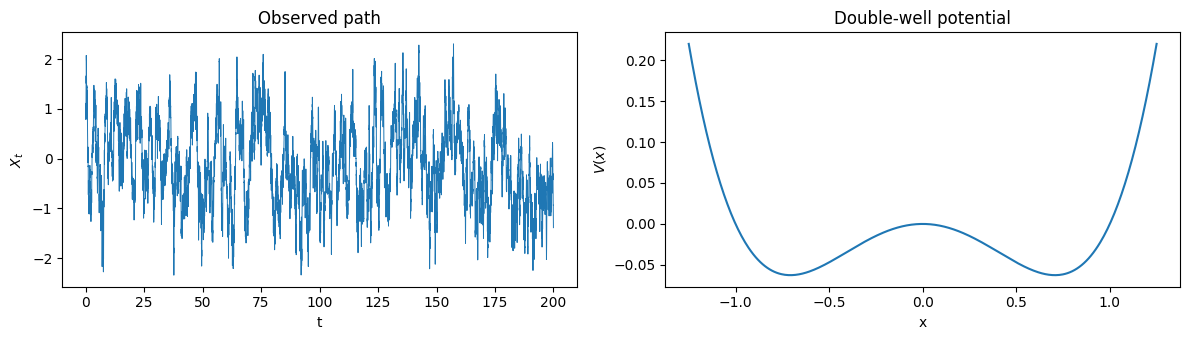

In [4]:
%run -i ../../data_generation/double_well.py

assert np.isfinite(S_).all()
assert np.allclose(np.diff(S_), mu_exact_[:-1] * dt + sigma_exact_[:-1] * np.diff(W_))
print(f'N = {N:,}, T = {T:g}, dt = {dt:g}, seed = {seed}')
print(f'Observed range: [{S_.min():.3f}, {S_.max():.3f}]')
print(f'Time below zero: {np.mean(S_ < 0):.1%}')

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(t[::100], S_[::100], lw=0.7)
axes[0].set(xlabel='t', ylabel=r'$X_t$', title='Observed path')
x_grid = np.linspace(-1.25, 1.25, 400)
axes[1].plot(x_grid, x_grid**4 / 4 - x_grid**2 / 4)
axes[1].set(xlabel='x', ylabel=r'$V(x)$', title='Double-well potential')
fig.tight_layout()
fig.savefig('path.png', dpi=180)
plt.show()

## Estimate $\sigma$

Use a degree-4 polynomial for $\sigma^2$. Select SR3 settings on the final 20%
of the trajectory, with a three-sample gap after training. Reject nonconverged
fits and nonpositive variance. Refit the selected model on all observations.
The actual diffusion is used only to report errors, not for selection.
Derivatives are calculated from the fitted polynomial.

In [5]:
%run -i ../../models/quadratic_variation_cumulative.py

thresholds = [0.1, 1.0, 3.0, 10.0]
nus = [0.1, 0.5, 2.0]
model, sigma_settings, sigma_search = fit_diffusion(S_, t, dQV, thresholds, nus)
diffusion_coefficients = model.coefficients()[0].copy()
sigma_pred_ = np.sqrt(model.predict(S_.reshape(-1, 1))).ravel()
sigma_equation = model.equations(precision=8)[0]
sigma_rmse = rmse(sigma_pred_, sigma_exact_)
print('sigma^2(X) =', sigma_equation)
print(f"threshold = {sigma_settings['threshold']}, nu = {sigma_settings['nu']}")
print(f'Diffusion RMSE: {sigma_rmse:.6g}')
(RESULTS / 'diffusion_tuning.json').write_text(json.dumps(sigma_search, indent=2))

sigma^2(X) = 1.00198797 1 + 0.50032259 X^2 + 0.05995041 X^4
threshold = 1.0, nu = 0.5
Diffusion RMSE: 0.00170021


2004

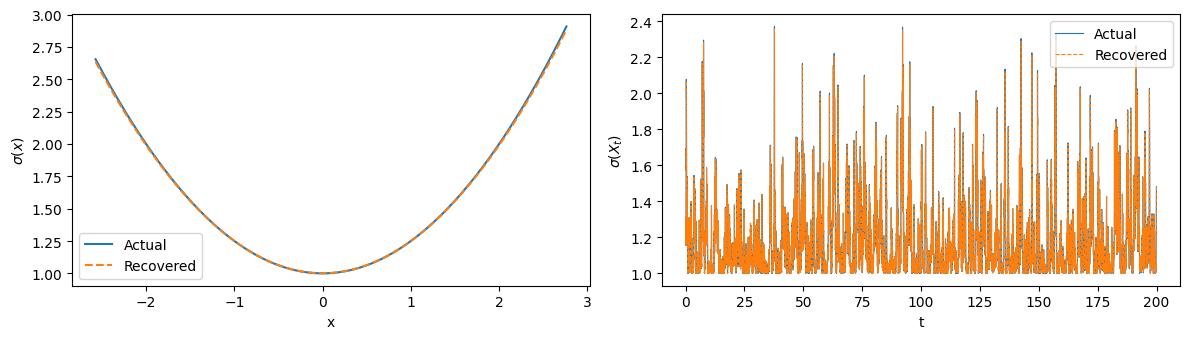

In [6]:
state_grid = np.linspace(S_.min(), S_.max(), 500)
sigma_grid = np.sqrt(polyval(state_grid, diffusion_coefficients))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(state_grid, sigma(state_grid), label='Actual')
axes[0].plot(state_grid, sigma_grid, '--', label='Recovered')
axes[0].set(xlabel='x', ylabel=r'$\sigma(x)$')
axes[1].plot(t[::100], sigma_exact_[::100], label='Actual', lw=0.8)
axes[1].plot(t[::100], sigma_pred_[::100], '--', label='Recovered', lw=0.8)
axes[1].set(xlabel='t', ylabel=r'$\sigma(X_t)$')
for ax in axes:
    ax.legend()
fig.tight_layout()
fig.savefig('diffusion.png', dpi=180)
plt.show()

## Recover $B^Q$ and estimate $\psi_{21}$

In [7]:
%run -i ../../models/q_brownian_motion.py

keep_cols = [0, 1, 3, 4, 5, 13]
%run -i ../../models/signature_regression.py
%run -i ../../data_generation/coarse_graining.py

sigma_prime, sigma_2prime, sigma_3prime = diffusion_derivatives(diffusion_coefficients, S)
t_ = t[::M]
dt_coarse = M * dt
print(f'Signature window: {M} samples; coarse dt = {dt_coarse:g}')

  0%|          | 0/10000 [00:00<?, ?it/s]

  2%|▏         | 195/10000 [00:00<00:05, 1948.19it/s]

  4%|▍         | 396/10000 [00:00<00:04, 1979.05it/s]

  6%|▌         | 594/10000 [00:00<00:04, 1958.78it/s]

  8%|▊         | 790/10000 [00:00<00:04, 1948.47it/s]

...

 96%|█████████▌| 9580/10000 [00:04<00:00, 2005.95it/s]

 98%|█████████▊| 9785/10000 [00:04<00:00, 2017.07it/s]

100%|█████████▉| 9987/10000 [00:05<00:00, 2015.35it/s]

100%|██████████| 10000/10000 [00:05<00:00, 1962.38it/s]

Signature window: 100 samples; coarse dt = 0.02


## Recover $\mu$

Use the existing drift equations without modification. ODE2 is conditional on
the supplied initial slope. No estimated-slope experiment is included.

In [8]:
%run -i ../../models/drift_coefficients.py
%run -i ../../models/drift_recovery.py

lambda_0 = 0.5 - 3 * S0**2
%run -i ../../models/drift_recovery_from_ODE2.py
mu_ode2_known = mu_pred11.copy()

### Comparison from observed increments

Fit $\Delta X_i\approx\mu(X_i)\Delta t$ with polynomial degrees 1--5 and ridge
penalties 0, 0.01, 0.1, 1, and 10. Use five expanding time-series folds.
Choose the smallest degree within one standard error of the best validation
score, then the best penalty at that degree. Refit on the full path.

The validation score subtracts the same zero-drift error from every candidate;
negative scores are therefore allowed. This fit uses a long observation period
and is separate from signature-based drift recovery. Neither the actual drift
nor the Brownian path enters the fit or selection.

In [9]:
with threadpool_limits(limits=1):
    increment_coefficients, drift_settings, drift_search = fit_increment_drift(S_, dt)
mu_increment = polyval(S, increment_coefficients)
print('Increment drift coefficients:', increment_coefficients)
print(f"Selected degree: {drift_settings['degree']}; penalty: {drift_settings['penalty']}")
(RESULTS / 'drift_tuning.json').write_text(json.dumps(drift_search, indent=2))

drift_estimates = {
    'Method 1': mu_pred1,
    'Method 2': mu_pred2,
    'ODE2 (known slope)': mu_ode2_known,
    'Increment fit': mu_increment,
}
drift_rmse = {name: rmse(estimate, mu_exact) for name, estimate in drift_estimates.items()}

Increment drift coefficients: [-0.09670975  0.76342307 -0.05369468 -1.18525967]
Selected degree: 3; penalty: 1.0


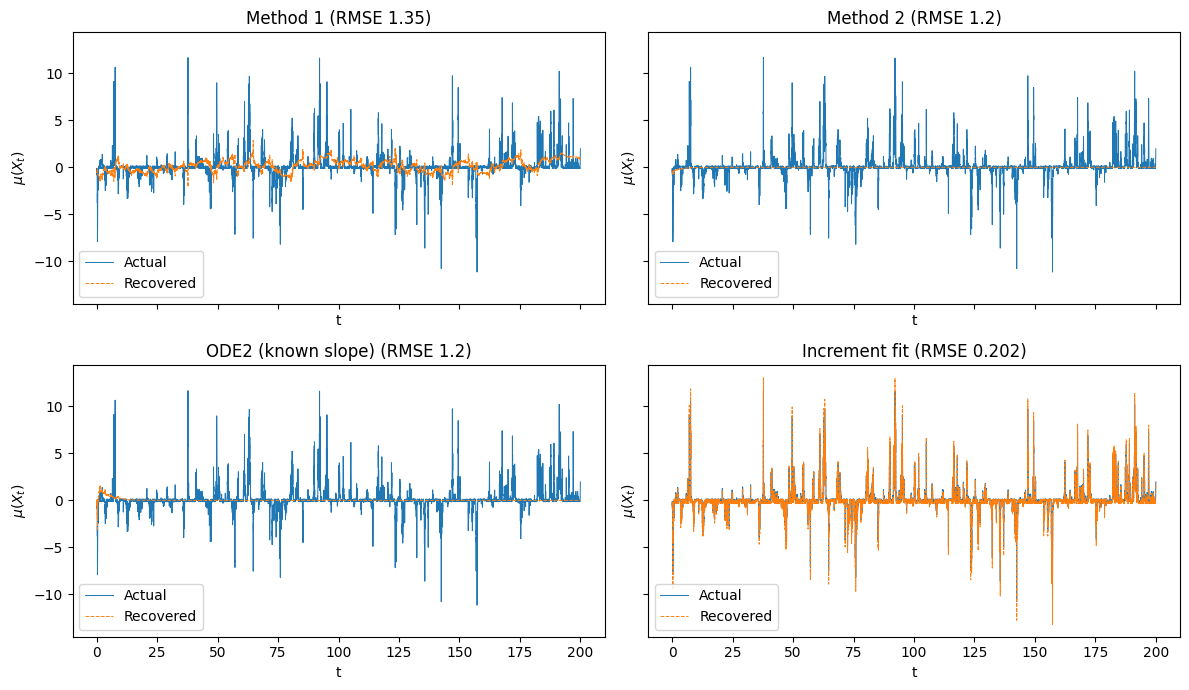

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, sharey=True)
for ax, (name, estimate) in zip(axes.flat, drift_estimates.items()):
    ax.plot(t_, mu_exact, label='Actual', lw=0.7)
    ax.plot(t_, estimate, '--', label='Recovered', lw=0.7)
    ax.set(title=f'{name} (RMSE {drift_rmse[name]:.3g})', xlabel='t', ylabel=r'$\mu(X_t)$')
    ax.legend()
fig.tight_layout()
fig.savefig('drift_comparison.png', dpi=180)
plt.show()

### Check the drift equations

Method 2 has $b=0$, so its continuous equation preserves $\mu/\sigma$.
That ratio is not constant for this process. The left-point numerical scheme
can also accumulate error along the fluctuating path.

The existing ODE2 requires $\mu''=A\mu'+B\mu$. Evaluate this identity using
only the exact functions as a diagnostic. A nonzero residual means that tuning
the diffusion regression cannot make this ODE exact for the double well.
This check does not supply values to the recovery algorithms.

See Remark 3.1 and Section 4.1.5 of the
[noise-estimation paper](https://arxiv.org/html/2509.25484v2).

Exact ODE2 residual at X0: -3.64


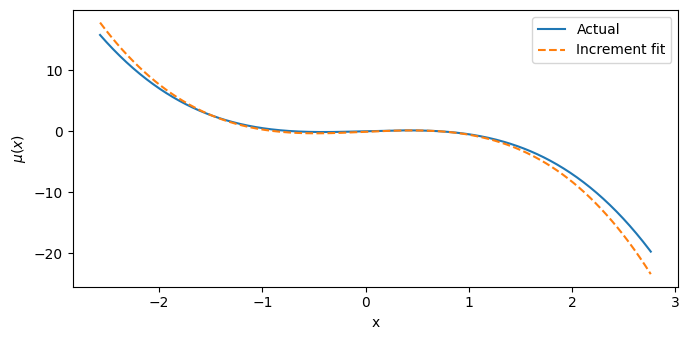

In [11]:
sigma0 = sigma(S0)
A0 = S0 / sigma0
B0 = 0.5 / sigma0 + 0.5 * S0**2 / sigma0**2
ode2_residual_at_start = -6 * S0 - A0 * (0.5 - 3 * S0**2) - B0 * mu(S0)
print(f'Exact ODE2 residual at X0: {ode2_residual_at_start:.6g}')

plt.figure(figsize=(7, 3.5))
plt.plot(state_grid, mu(state_grid), label='Actual')
plt.plot(state_grid, polyval(state_grid, increment_coefficients), '--', label='Increment fit')
plt.xlabel('x')
plt.ylabel(r'$\mu(x)$')
plt.legend()
plt.tight_layout()
plt.savefig('increment_drift.png', dpi=180)
plt.show()

## Recover $B^P$

Use the same recovered $B^Q$, diffusion, and coarse time grid for all four drift
estimates. The actual Brownian path is used only to measure error.

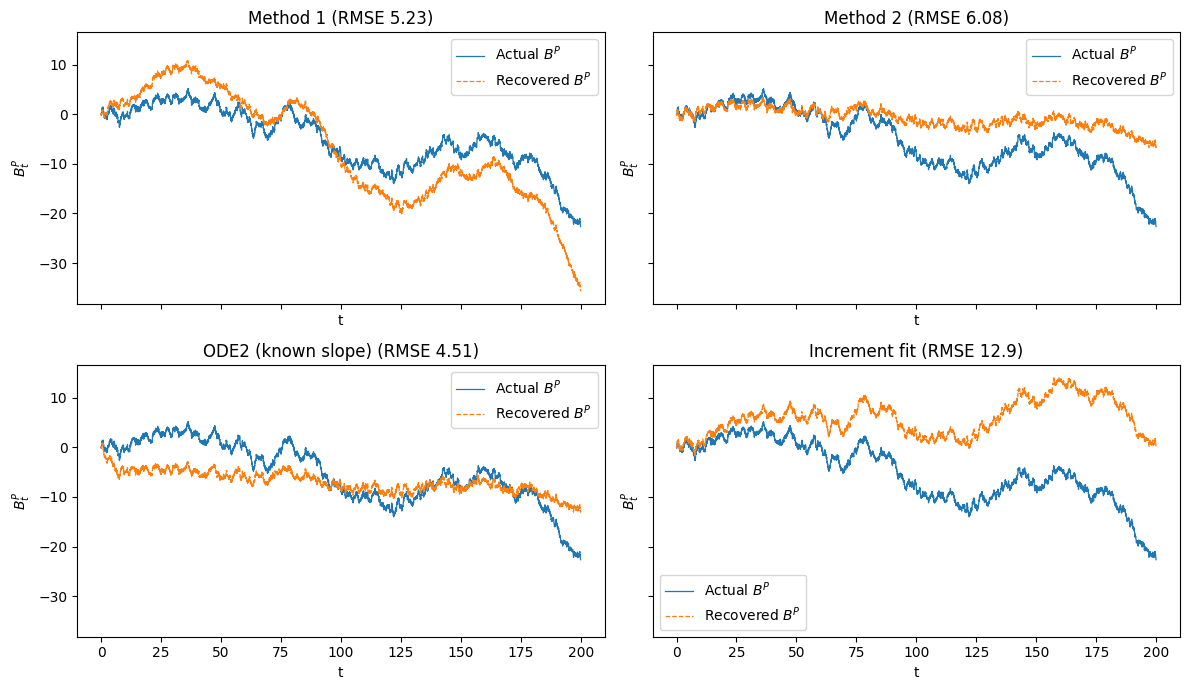

In [12]:
noise_estimates = {
    name: recover_noise(BQ, estimate, sigma_pred, dt_coarse)
    for name, estimate in drift_estimates.items()
}
noise_rmse = {name: rmse(noise, W) for name, noise in noise_estimates.items()}
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, sharey=True)
for ax, (name, noise) in zip(axes.flat, noise_estimates.items()):
    ax.plot(t_, W, label=r'Actual $B^P$', lw=0.9)
    ax.plot(t_, noise, '--', label=r'Recovered $B^P$', lw=0.9)
    ax.set(title=f'{name} (RMSE {noise_rmse[name]:.3g})', xlabel='t', ylabel=r'$B_t^P$')
    ax.legend()
fig.tight_layout()
fig.savefig('noise_comparison.png', dpi=180)
plt.show()

## SSISDE

For every recovered noise path, use degree-5 drift and diffusion libraries,
five time-series folds, and the one-standard-error rule. This stage can inherit
errors in the recovered noise. A small increment error does not independently
validate the drift or noise. The displayed errors are for the fitted trajectory.

In [13]:
%run -i ../../models/stochastic_sindy.py

identifiers = {}
method_results = {}
with threadpool_limits(limits=1):
    for name, noise in noise_estimates.items():
        identifier = StochSINDy(
            mu_deg=5, si_deg=5, pen='elasticnet', use_cv=True, k=5,
            alphas=np.geomspace(1e-6, 1.0, 21),
            rhos=[0.5, 0.9, 1.0], use_1se=True,
        )
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always', ConvergenceWarning)
            identifier.fit(S, noise, dt_coarse)
        identifiers[name] = identifier
        method_results[name] = {
            'drift_rmse': drift_rmse[name],
            'noise_rmse': noise_rmse[name],
            'noise_increment_rmse': rmse(np.diff(noise), np.diff(W)),
            'ssisde_increment_mse': identifier.mse,
            'ssisde_drift_rmse': rmse(identifier.mu(S), mu_exact),
            'ssisde_diffusion_rmse': rmse(identifier.si(S), sigma_exact),
            'mu': identifier._fmt_poly(identifier.mu_c),
            'sigma': identifier._fmt_poly(identifier.si_c),
            'mu_coefficients': identifier.mu_c.tolist(),
            'sigma_coefficients': identifier.si_c.tolist(),
            'alpha': identifier.best_a,
            'rho': identifier.best_r,
            'convergence_warnings': sum(issubclass(w.category, ConvergenceWarning) for w in caught),
        }
        print(name)
        identifier.show()
        if method_results[name]['convergence_warnings']:
            print('Convergence warnings:', method_results[name]['convergence_warnings'])

Method 1
MSE: 2.134e-04
μ(X) = 0
σ(X) = 1.00539 + 0.224482*X^2
[CV best] alpha=0.0631, l1_ratio (rho)=0.50


Method 2
MSE: 5.204e-05
μ(X) = 0
σ(X) = 1.01093 + 0.226939*X^2
[CV best] alpha=0.0631, l1_ratio (rho)=0.50


ODE2 (known slope)
MSE: 5.967e-05
μ(X) = 0
σ(X) = 1.0104 + 0.227229*X^2
[CV best] alpha=0.0631, l1_ratio (rho)=0.50


Increment fit
MSE: 5.106e-05
μ(X) = -0.134658 + 0.78397*X + -1.24729*X^3 + 0.0191861*X^5
σ(X) = 1.0118 + 0.224452*X^2
[CV best] alpha=0.002, l1_ratio (rho)=0.50


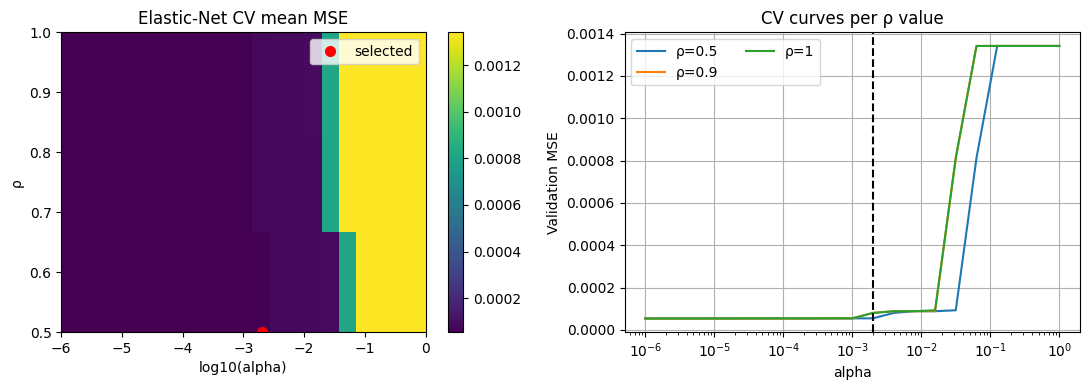

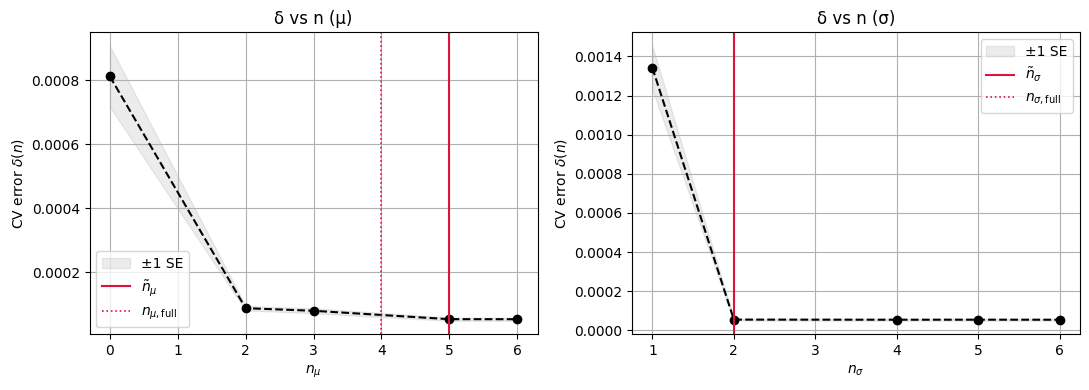

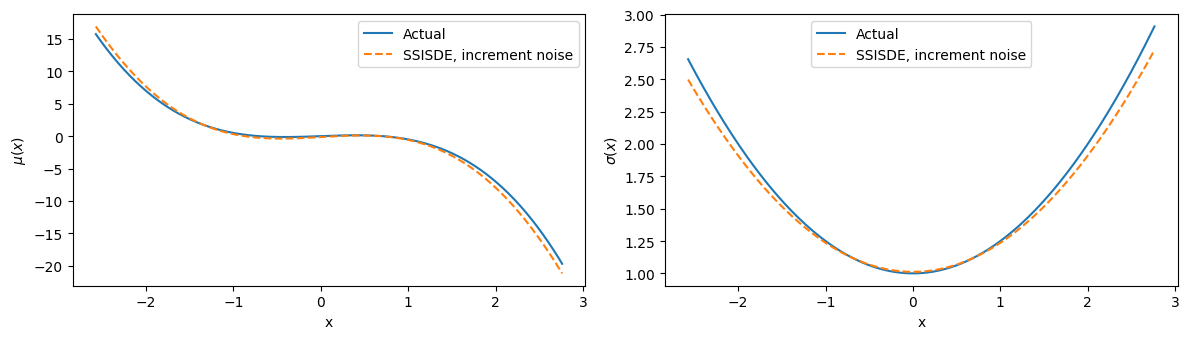

In [14]:
identifier = identifiers['Increment fit']
model = 'double_well_increment'
identifier.plot_cv()
identifier.plot_size(count_bias=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(state_grid, mu(state_grid), label='Actual')
axes[0].plot(state_grid, identifier.mu(state_grid), '--', label='SSISDE, increment noise')
axes[0].set(xlabel='x', ylabel=r'$\mu(x)$')
axes[1].plot(state_grid, sigma(state_grid), label='Actual')
axes[1].plot(state_grid, identifier.si(state_grid), '--', label='SSISDE, increment noise')
axes[1].set(xlabel='x', ylabel=r'$\sigma(x)$')
for ax in axes:
    ax.legend()
fig.tight_layout()
fig.savefig('ssisde_comparison.png', dpi=180)
plt.show()

## Fit with double-well symmetry

As a separate comparison, supply the symmetry $\mu(-x)=-\mu(x)$, so the drift
library contains odd powers only. Select degrees 1, 3, or 5 and the same ridge
penalties with the same five-fold rule. The fitted coefficients, initial drift,
and initial slope are not supplied. This symmetry is additional information
from the stated model, not something discovered by this fit.

Recover the noise on the same coarse grid, then run the general degree-5
SSISDE libraries using that noise. Small drift biases can accumulate over
$T=200$, so we report both Brownian-path and Brownian-increment errors.

In [15]:
with threadpool_limits(limits=1):
    odd_coefficients, odd_settings, odd_search = fit_increment_drift(
        S_, dt, degrees=(1, 3, 5), odd=True,
    )
mu_odd = polyval(S, odd_coefficients)
BP_odd = recover_noise(BQ, mu_odd, sigma_pred, dt_coarse)
odd_identifier = StochSINDy(
    mu_deg=5, si_deg=5, pen='elasticnet', use_cv=True, k=5,
    alphas=np.geomspace(1e-6, 1.0, 21), rhos=[0.5, 0.9, 1.0], use_1se=True,
)
with threadpool_limits(limits=1), warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always', ConvergenceWarning)
    odd_identifier.fit(S, BP_odd, dt_coarse)
odd_fit = {
    'supplied_information': 'Odd drift symmetry; no known coefficients or initial drift',
    'settings': odd_settings,
    'drift_coefficients': odd_coefficients.tolist(),
    'drift_equation': odd_identifier._fmt_poly(odd_coefficients),
    'drift_rmse': rmse(mu_odd, mu_exact),
    'noise_rmse': rmse(BP_odd, W),
    'noise_increment_rmse': rmse(np.diff(BP_odd), np.diff(W)),
    'ssisde_increment_mse': odd_identifier.mse,
    'ssisde_drift_rmse': rmse(odd_identifier.mu(S), mu_exact),
    'ssisde_diffusion_rmse': rmse(odd_identifier.si(S), sigma_exact),
    'mu': odd_identifier._fmt_poly(odd_identifier.mu_c),
    'sigma': odd_identifier._fmt_poly(odd_identifier.si_c),
    'mu_coefficients': odd_identifier.mu_c.tolist(),
    'sigma_coefficients': odd_identifier.si_c.tolist(),
    'alpha': odd_identifier.best_a, 'rho': odd_identifier.best_r,
    'convergence_warnings': sum(issubclass(w.category, ConvergenceWarning) for w in caught),
}
(RESULTS / 'odd_drift_tuning.json').write_text(json.dumps(odd_search, indent=2))
print('Odd increment drift:', odd_fit['drift_equation'])
print(f"Selected degree: {odd_settings['degree']}; penalty: {odd_settings['penalty']}")
print(f"Drift RMSE: {odd_fit['drift_rmse']:.6g}; Brownian path RMSE: {odd_fit['noise_rmse']:.6g}")
odd_identifier.show()
if odd_fit['convergence_warnings']:
    print('Convergence warnings:', odd_fit['convergence_warnings'])

Odd increment drift: 0.782957*X + -1.17707*X^3
Selected degree: 3; penalty: 1.0
Drift RMSE: 0.149874; Brownian path RMSE: 0.390244
MSE: 5.020e-05
μ(X) = 0.815064*X + -1.25383*X^3 + 0.0202219*X^5
σ(X) = 1.01177 + 0.224561*X^2
[CV best] alpha=0.002, l1_ratio (rho)=0.50


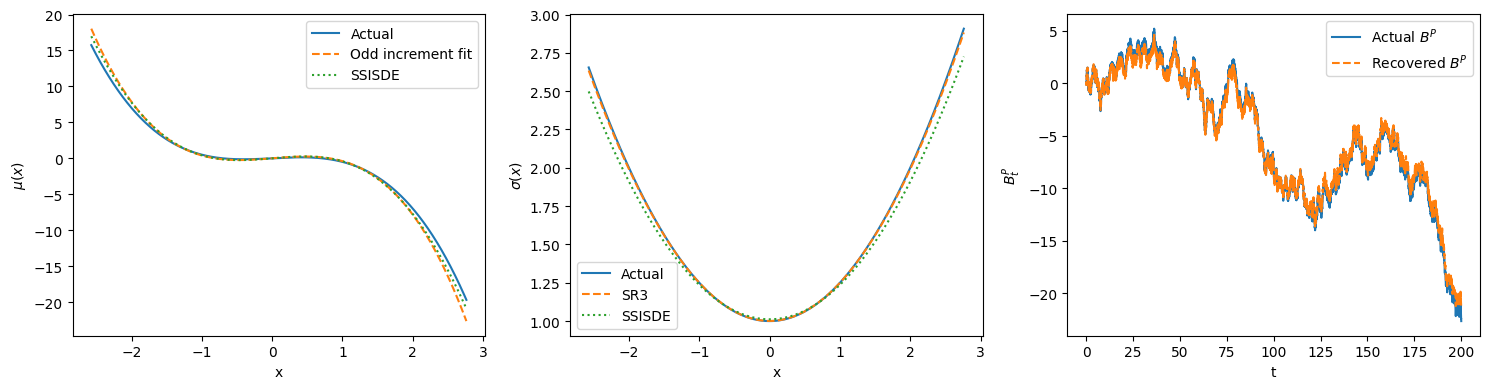

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(state_grid, mu(state_grid), label='Actual')
axes[0].plot(state_grid, polyval(state_grid, odd_coefficients), '--', label='Odd increment fit')
axes[0].plot(state_grid, odd_identifier.mu(state_grid), ':', label='SSISDE')
axes[0].set(xlabel='x', ylabel=r'$\mu(x)$')
axes[1].plot(state_grid, sigma(state_grid), label='Actual')
axes[1].plot(state_grid, sigma_grid, '--', label='SR3')
axes[1].plot(state_grid, odd_identifier.si(state_grid), ':', label='SSISDE')
axes[1].set(xlabel='x', ylabel=r'$\sigma(x)$')
axes[2].plot(t_, W, label=r'Actual $B^P$')
axes[2].plot(t_, BP_odd, '--', label=r'Recovered $B^P$')
axes[2].set(xlabel='t', ylabel=r'$B_t^P$')
for ax in axes:
    ax.legend()
fig.tight_layout()
fig.savefig('double_well_symmetry.png', dpi=180)
plt.show()

## Results

In [17]:
results = {
    'experiment': 'Double well',
    'seed': seed, 'samples': N, 'T': T, 'dt': dt, 'X0': S0,
    'coarse_step': M, 'dt_coarse': dt_coarse,
    'actual_mu': '0.5*X - X^3', 'actual_sigma': '1 + 0.25*X^2',
    'supplied_initial_drift': mu_0, 'supplied_initial_slope': lambda_0,
    'state_range': [float(S_.min()), float(S_.max())],
    'fraction_below_zero': float(np.mean(S_ < 0)),
    'sigma_settings': sigma_settings,
    'sigma_squared_equation': sigma_equation,
    'sigma_squared_coefficients': diffusion_coefficients.tolist(),
    'sigma_rmse': sigma_rmse,
    'increment_drift_settings': drift_settings,
    'increment_drift_coefficients': increment_coefficients.tolist(),
    'increment_drift_equation': identifier._fmt_poly(increment_coefficients),
    'ode2_exact_residual_at_start': ode2_residual_at_start,
    'methods': method_results,
    'odd_drift_comparison': odd_fit,
}
(RESULTS / 'results.json').write_text(json.dumps(results, indent=2, allow_nan=False))
np.savez_compressed(RESULTS / 'paths.npz', t=t_, S=S, W=W, BQ=BQ,
                    mu_exact=mu_exact, sigma_exact=sigma_exact, sigma_pred=sigma_pred,
                    drift=np.array(list(drift_estimates.values())),
                    noise=np.array(list(noise_estimates.values())),
                    methods=np.array(list(drift_estimates)), mu_odd=mu_odd, BP_odd=BP_odd)
print(f"{'Method':26} {'Drift RMSE':>12} {'Noise RMSE':>12} {'SSISDE drift':>14}")
for name, row in [*method_results.items(), ('Odd increment fit', odd_fit)]:
    print(f"{name:26} {row['drift_rmse']:12.6g} {row['noise_rmse']:12.6g} {row['ssisde_drift_rmse']:14.6g}")
print('Numerical results:', RESULTS / 'results.json')

Method                       Drift RMSE   Noise RMSE   SSISDE drift
Method 1                         1.3474      5.23013        1.20027
Method 2                        1.19774      6.07945        1.20027
ODE2 (known slope)               1.2015      4.50521        1.20027
Increment fit                  0.201668      12.8687       0.197696
Odd increment fit              0.149874     0.390244       0.146471
Numerical results: /Users/munawarali/Documents/GitHub/SSISDE/outputs/double_well/results.json


The diffusion and drift searches use observed data, with no search over random
seeds or the true coefficients. The reported errors use the simulated truth
for comparison. The three existing drift methods use the known initial drift;
ODE2 also uses the known initial slope. The increment comparison supplies neither.

The double well violates the existing drift-equation restrictions, so accurate
diffusion alone does not establish accurate drift recovery. The separate increment
fit relies on observing the process for a longer period. These are results from
one simulated trajectory, not a claim of reliability across all paths.

Supplying odd drift symmetry improves the Brownian-path comparison in this run.
This improvement uses additional model information and is reported separately.
The unrestricted increment fit has a lower drift error than the original
methods but a larger accumulated noise error; both are retained above.